# Assertion Regression Report: Qwen-8B Fallback

This notebook compares the known **36-point submission** with the current pipeline that uses **Qwen-8B as an assertion fallback**. It is designed as a debugging report, not merely a score summary.

The analysis answers four questions:

1. How much of the change comes from different entities rather than assertions?
2. On identical entities, which assertion labels changed?
3. Which changes were produced specifically by Qwen fallback?
4. What linguistic patterns and concrete cases explain the regression?

> **Important:** the 36-point output is a strong reference because it scored better, but it is not hidden ground truth. Agreement with it is therefore a regression proxy, not true accuracy.

In [1]:
from pathlib import Path
import json
import re
import unicodedata
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 180)
pd.set_option('display.max_rows', 200)

# -----------------------------------------------------------------------------
# Paths: edit only these values if the outputs move.
# -----------------------------------------------------------------------------
BASELINE_DIR = Path(r'C:\Users\ACER\OneDrive\Desktop\output')
CURRENT_DIR = Path(r'D:\SIDE PROJECTS\Ontological Reasoning in Medical Knowledge Retrieval\data\output_merged_validation')
INTERMEDIATE_DIR = Path(r'D:\SIDE PROJECTS\Ontological Reasoning in Medical Knowledge Retrieval\data\output_merged_linking')
EXPORT_DIR = Path.cwd() / 'assertion_debug_report_outputs'

ASSERTION_ORDER = ['NONE', 'isNegated', 'isHistorical', 'isFamily']
PALETTE = {
    'baseline': '#355C7D',
    'current': '#F67280',
    'qwen': '#F8B195',
    'primary': '#6C5B7B',
    'good': '#2A9D8F',
    'warning': '#E9C46A',
    'bad': '#E76F51',
    'neutral': '#8D99AE',
}

sns.set_theme(style='whitegrid', context='notebook', font_scale=1.05)
plt.rcParams.update({
    'figure.figsize': (11, 6),
    'figure.dpi': 115,
    'axes.titleweight': 'bold',
    'axes.titlesize': 14,
    'axes.labelsize': 11,
    'legend.frameon': False,
})

for name, folder in {
    '36-point baseline': BASELINE_DIR,
    'current final output': CURRENT_DIR,
    'current intermediate output': INTERMEDIATE_DIR,
}.items():
    if not folder.exists():
        raise FileNotFoundError(f'{name} does not exist: {folder}')

print('Baseline:', BASELINE_DIR)
print('Current final:', CURRENT_DIR)
print('Intermediate with Qwen metadata:', INTERMEDIATE_DIR)

Baseline: C:\Users\ACER\OneDrive\Desktop\output
Current final: D:\SIDE PROJECTS\Ontological Reasoning in Medical Knowledge Retrieval\data\output_merged_validation
Intermediate with Qwen metadata: D:\SIDE PROJECTS\Ontological Reasoning in Medical Knowledge Retrieval\data\output_merged_linking


## Methodology

The two final outputs have original-document offsets, while the intermediate Qwen output has normalized-document offsets. The notebook therefore:

- aligns the current final output with its intermediate metadata by **file and entity order**;
- aligns baseline and current entities by **file, original position, text, type, and duplicate occurrence**;
- measures assertion changes only on this exact matched population;
- reports unmatched entities separately as an NER/preprocessing confound;
- attributes each current assertion to the primary rule, Qwen fallback, uncertain suppression, or an empty fallback.

In [2]:
def numeric_json_files(folder: Path):
    return sorted(
        [p for p in folder.glob('*.json') if p.stem.isdigit()],
        key=lambda p: int(p.stem),
    )


def assertion_tag(value):
    value = value or []
    if len(value) == 0:
        return 'NONE'
    if len(value) != 1:
        return '|'.join(sorted(map(str, value)))
    return str(value[0])


def load_final(folder: Path, version: str) -> pd.DataFrame:
    rows = []
    for path in numeric_json_files(folder):
        entities = json.loads(path.read_text(encoding='utf-8'))
        if not isinstance(entities, list):
            raise TypeError(f'Expected a list in {path}')
        for index, entity in enumerate(entities):
            position = entity.get('position', [None, None])
            rows.append({
                'file': path.name,
                'file_id': int(path.stem),
                'pipeline_index': index,
                'text': entity.get('text'),
                'type': entity.get('type'),
                'start': position[0],
                'end': position[1],
                'assertion_tag': assertion_tag(entity.get('assertions')),
                'candidates': tuple(entity.get('candidates', []) or []),
                'version': version,
            })
    frame = pd.DataFrame(rows)
    identity = ['file', 'start', 'end', 'text', 'type']
    frame['duplicate_rank'] = frame.groupby(identity, dropna=False).cumcount()
    return frame


def clean_primary_tag(value):
    if isinstance(value, dict):
        return value.get('tag')
    return None


def source_category(primary, qwen):
    if primary == 'isUncertain':
        return 'Primary uncertain → NONE'
    if primary is not None:
        return 'Primary rule'
    if qwen is not None:
        return 'Qwen fallback'
    return 'Fallback empty'


def load_intermediate(folder: Path) -> pd.DataFrame:
    rows = []
    for path in numeric_json_files(folder):
        entities = json.loads(path.read_text(encoding='utf-8'))
        for index, entity in enumerate(entities):
            primary = clean_primary_tag(entity.get('assertion_result'))
            qwen = entity.get('qwen_assertion')
            rows.append({
                'file': path.name,
                'intermediate_index': index,
                'text': entity.get('text'),
                'type': entity.get('type'),
                'normalized_position': tuple(entity.get('position', []) or []),
                'sentence': entity.get('sentence', ''),
                'primary_tag': primary,
                'qwen_tag': qwen,
                'source_category': source_category(primary, qwen),
            })
    frame = pd.DataFrame(rows)
    frame['metadata_duplicate_rank'] = frame.groupby(
        ['file', 'text', 'type'], dropna=False
    ).cumcount()
    return frame


baseline = load_final(BASELINE_DIR, '36-point baseline')
current = load_final(CURRENT_DIR, 'Qwen-8B fallback')
intermediate = load_intermediate(INTERMEDIATE_DIR)

# Attach primary/Qwen provenance by entity identity instead of raw row index.
# The final formatter reorders two adjacent lab entities in file 38.
current['metadata_duplicate_rank'] = current.groupby(
    ['file', 'text', 'type'], dropna=False
).cumcount()
current = current.merge(
    intermediate,
    on=['file', 'text', 'type', 'metadata_duplicate_rank'],
    how='left',
    validate='one_to_one',
    indicator='_metadata_merge',
)
metadata_mismatch = current[current['_metadata_merge'] != 'both']
if len(metadata_mismatch):
    raise AssertionError(f'{len(metadata_mismatch)} entities lack intermediate metadata')
current = current.drop(columns=['_metadata_merge'])

match_columns = ['file', 'start', 'end', 'text', 'type', 'duplicate_rank']
matched = baseline.merge(
    current,
    on=match_columns,
    how='inner',
    suffixes=('_baseline', '_current'),
    validate='one_to_one',
)
matched['changed'] = matched['assertion_tag_baseline'] != matched['assertion_tag_current']
matched['agreement'] = ~matched['changed']

entity_outer = baseline[match_columns].merge(
    current[match_columns],
    on=match_columns,
    how='outer',
    indicator=True,
)
old_only = entity_outer[entity_outer['_merge'] == 'left_only']
new_only = entity_outer[entity_outer['_merge'] == 'right_only']

validation = pd.DataFrame({
    'check': ['Baseline JSON files', 'Current JSON files', 'Intermediate JSON files',
              'Baseline entities', 'Current entities', 'Exactly matched entities',
              'Baseline-only/mutated entities', 'Current-only/mutated entities',
              'Current entities lacking intermediate metadata'],
    'value': [len(numeric_json_files(BASELINE_DIR)), len(numeric_json_files(CURRENT_DIR)),
              len(numeric_json_files(INTERMEDIATE_DIR)), len(baseline), len(current),
              len(matched), len(old_only), len(new_only), len(metadata_mismatch)],
})
display(validation.style.hide(axis='index').format({'value': '{:,}'}))

check,value
Baseline JSON files,100
Current JSON files,100
Intermediate JSON files,100
Baseline entities,"2,227"
Current entities,"2,236"
Exactly matched entities,"2,016"
Baseline-only/mutated entities,211
Current-only/mutated entities,220
Current entities lacking intermediate metadata,0


## 1. Executive score decomposition

The current leaderboard metrics are included here to show where the final score is coming from. This is not a reimplementation of the hidden evaluator.

Final score = 29.85889


component,raw_score,weight,weighted_contribution
Text,43.3827,0.3,13.0148
Assertions,37.9896,0.3,11.3969
Candidates,13.6180,0.4,5.4472


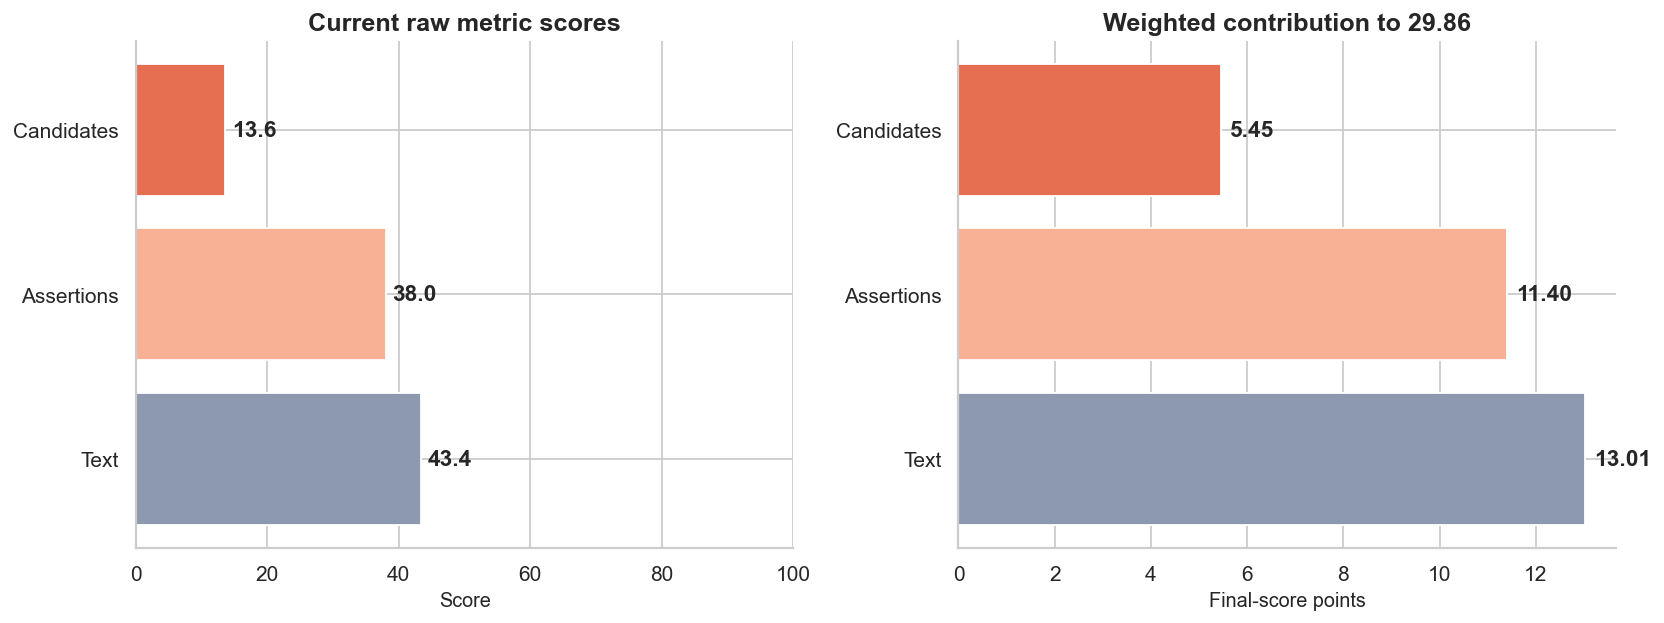

In [3]:
score_components = pd.DataFrame({
    'component': ['Text', 'Assertions', 'Candidates'],
    'raw_score': [43.3827, 37.9896, 13.6180],
    'weight': [0.3, 0.3, 0.4],
})
score_components['weighted_contribution'] = score_components['raw_score'] * score_components['weight']
final_score = score_components['weighted_contribution'].sum()

display(score_components.style.hide(axis='index').format({
    'raw_score': '{:.4f}', 'weight': '{:.1f}', 'weighted_contribution': '{:.4f}'
}))
print(f'Final score = {final_score:.5f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = [PALETTE['neutral'], PALETTE['qwen'], PALETTE['bad']]
axes[0].barh(score_components['component'], score_components['raw_score'], color=colors)
axes[0].set_xlim(0, 100)
axes[0].set_title('Current raw metric scores')
axes[0].set_xlabel('Score')
for i, value in enumerate(score_components['raw_score']):
    axes[0].text(value + 1, i, f'{value:.1f}', va='center', fontweight='bold')

axes[1].barh(score_components['component'], score_components['weighted_contribution'], color=colors)
axes[1].set_title(f'Weighted contribution to {final_score:.2f}')
axes[1].set_xlabel('Final-score points')
for i, value in enumerate(score_components['weighted_contribution']):
    axes[1].text(value + 0.2, i, f'{value:.2f}', va='center', fontweight='bold')

sns.despine()
plt.tight_layout()
plt.show()

## 2. Entity drift: the non-Qwen confound

Qwen classifies assertions for entities it receives; it does not decide the entity spans. Any baseline/current entity mismatch must therefore be analyzed separately.

Only 27/100 files preserve the complete entity sequence and offsets.
Assertion attribution below is restricted to exact matched entities.


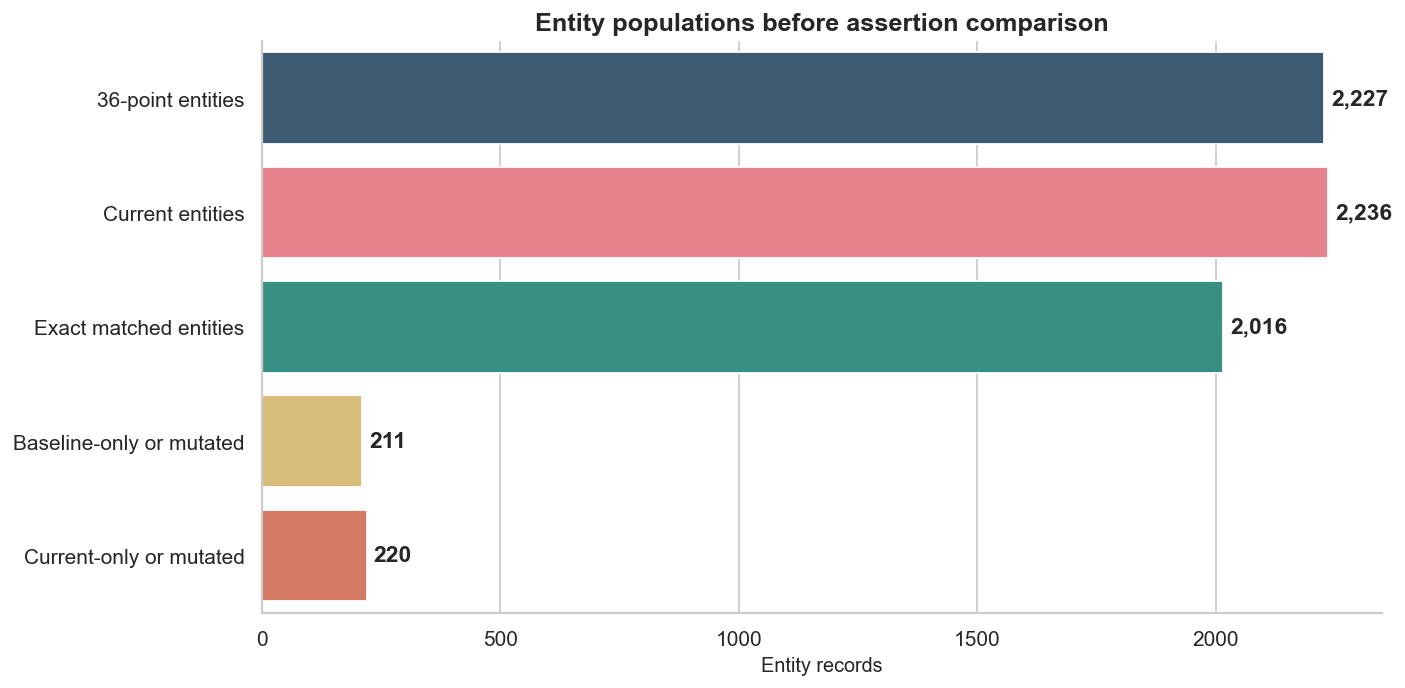

In [4]:
entity_summary = pd.DataFrame({
    'population': ['36-point entities', 'Current entities', 'Exact matched entities',
                   'Baseline-only or mutated', 'Current-only or mutated'],
    'count': [len(baseline), len(current), len(matched), len(old_only), len(new_only)],
})

fig, ax = plt.subplots(figsize=(11, 5.5))
bar_colors = [PALETTE['baseline'], PALETTE['current'], PALETTE['good'], PALETTE['warning'], PALETTE['bad']]
sns.barplot(data=entity_summary, x='count', y='population', palette=bar_colors, ax=ax)
ax.set_title('Entity populations before assertion comparison')
ax.set_xlabel('Entity records')
ax.set_ylabel('')
for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', padding=4, fontweight='bold')
sns.despine()
plt.tight_layout()
plt.show()

files_exact = 0
for file_name in sorted(set(baseline['file']) & set(current['file']), key=lambda x: int(Path(x).stem)):
    b = baseline[baseline['file'] == file_name][['text', 'type', 'start', 'end']].reset_index(drop=True)
    c = current[current['file'] == file_name][['text', 'type', 'start', 'end']].reset_index(drop=True)
    files_exact += int(b.equals(c))

print(f'Only {files_exact}/100 files preserve the complete entity sequence and offsets.')
print('Assertion attribution below is restricted to exact matched entities.')

## 3. Assertion distribution and transition matrix

The transition matrix is the fastest way to see whether the fallback is adding labels, deleting labels, or changing one positive label into another.

,36-point baseline,Qwen-8B fallback
assertion_tag,,
NONE,"1,864","1,715"
isNegated,94,265
isHistorical,136,212
isFamily,133,44


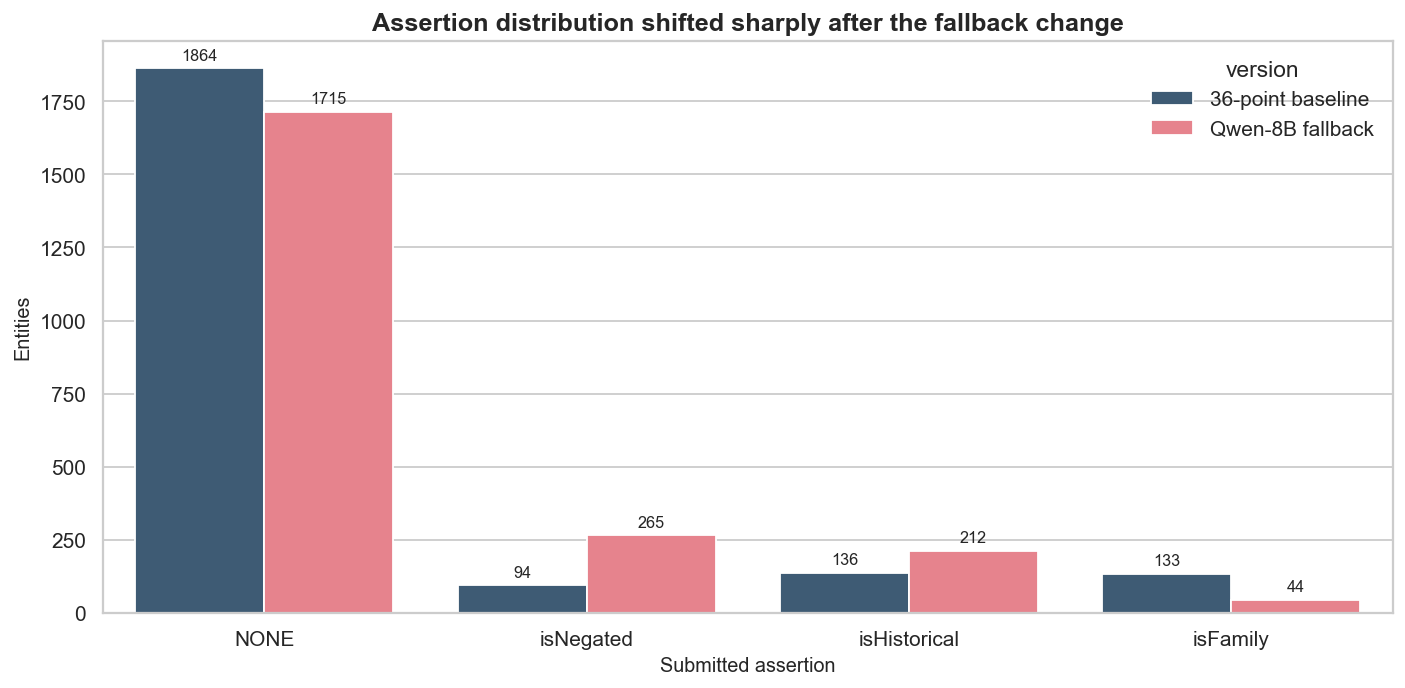

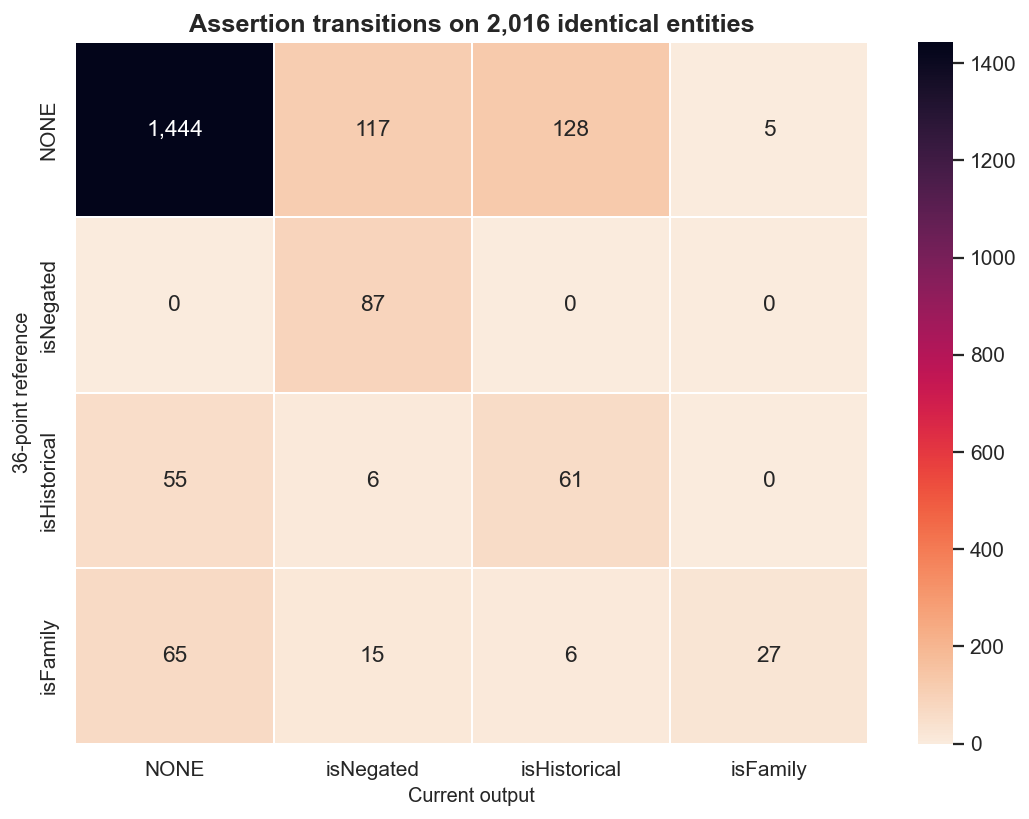

assertion_tag_baseline,assertion_tag_current,count
NONE,isHistorical,128
NONE,isNegated,117
isFamily,NONE,65
isHistorical,NONE,55
isFamily,isNegated,15
isFamily,isHistorical,6
isHistorical,isNegated,6
NONE,isFamily,5


In [5]:
distribution = pd.concat([
    baseline['assertion_tag'].value_counts().rename('36-point baseline'),
    current['assertion_tag'].value_counts().rename('Qwen-8B fallback'),
], axis=1).fillna(0).reindex(ASSERTION_ORDER).fillna(0).astype(int)

display(distribution.style.format('{:,}').background_gradient(cmap='Blues', axis=0))

plot_distribution = distribution.reset_index(names='assertion').melt(
    id_vars='assertion', var_name='version', value_name='count'
)
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.barplot(
    data=plot_distribution,
    x='assertion', y='count', hue='version',
    palette=[PALETTE['baseline'], PALETTE['current']], ax=ax,
)
ax.set_title('Assertion distribution shifted sharply after the fallback change')
ax.set_xlabel('Submitted assertion')
ax.set_ylabel('Entities')
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3, fontsize=9)
plt.tight_layout()
plt.show()

transition = pd.crosstab(
    matched['assertion_tag_baseline'],
    matched['assertion_tag_current'],
).reindex(index=ASSERTION_ORDER, columns=ASSERTION_ORDER, fill_value=0)

fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(transition, annot=True, fmt=',d', cmap='rocket_r', linewidths=1, ax=ax)
ax.set_title(f'Assertion transitions on {len(matched):,} identical entities')
ax.set_xlabel('Current output')
ax.set_ylabel('36-point reference')
plt.tight_layout()
plt.show()

changed_transitions = (
    matched.loc[matched['changed']]
    .groupby(['assertion_tag_baseline', 'assertion_tag_current'])
    .size().rename('count').reset_index()
    .sort_values('count', ascending=False)
)
display(changed_transitions.style.hide(axis='index').format({'count': '{:,}'}))

## 4. Attribute the changes to Qwen versus the primary pipeline

`source_category` is reconstructed from the intermediate fields:

- **Primary rule:** `assertion_result.tag` contains a supported assertion.
- **Primary uncertain → NONE:** the primary result is `isUncertain`, which the formatter suppresses.
- **Qwen fallback:** primary tag is null and `qwen_assertion` supplies the submitted label.
- **Fallback empty:** neither stage supplies a label.

source_category,entities,changed_vs_reference,agreement_rate,change_rate
Fallback empty,"1,275",68,94.7%,5.3%
Primary uncertain → NONE,289,52,82.0%,18.0%
Qwen fallback,269,263,2.2%,97.8%
Primary rule,183,14,92.3%,7.7%


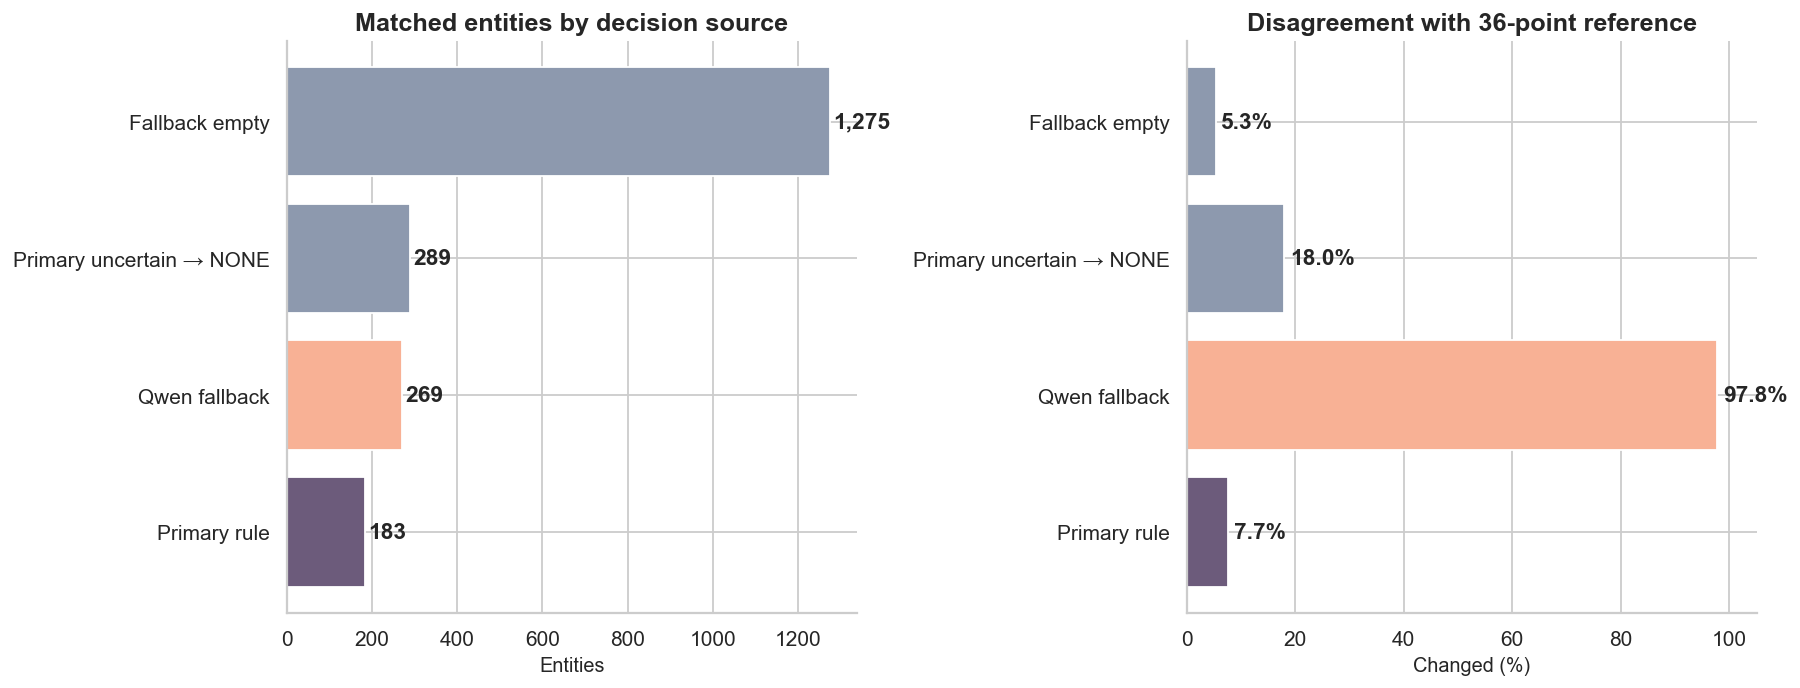

In [6]:
source_stats = (
    matched.groupby('source_category')
    .agg(
        entities=('changed', 'size'),
        changed_vs_reference=('changed', 'sum'),
        agreement_rate=('agreement', 'mean'),
    )
    .reset_index()
)
source_stats['change_rate'] = 1 - source_stats['agreement_rate']
source_stats = source_stats.sort_values('entities', ascending=False)

display(source_stats.style.hide(axis='index').format({
    'entities': '{:,}', 'changed_vs_reference': '{:,}',
    'agreement_rate': '{:.1%}', 'change_rate': '{:.1%}',
}).background_gradient(subset=['change_rate'], cmap='Reds'))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
source_colors = [
    PALETTE['qwen'] if x == 'Qwen fallback' else
    PALETTE['primary'] if x == 'Primary rule' else
    PALETTE['neutral']
    for x in source_stats['source_category']
]
axes[0].barh(source_stats['source_category'], source_stats['entities'], color=source_colors)
axes[0].invert_yaxis()
axes[0].set_title('Matched entities by decision source')
axes[0].set_xlabel('Entities')
for i, value in enumerate(source_stats['entities']):
    axes[0].text(value + 8, i, f'{value:,}', va='center', fontweight='bold')

axes[1].barh(source_stats['source_category'], source_stats['change_rate'] * 100, color=source_colors)
axes[1].invert_yaxis()
axes[1].set_xlim(0, 105)
axes[1].set_title('Disagreement with 36-point reference')
axes[1].set_xlabel('Changed (%)')
for i, value in enumerate(source_stats['change_rate'] * 100):
    axes[1].text(value + 1, i, f'{value:.1f}%', va='center', fontweight='bold')

sns.despine()
plt.tight_layout()
plt.show()

## 5. Qwen-only regression diagnostics

This section isolates exact matched entities whose submitted assertion came from Qwen. A prediction is marked as a **proxy false positive** when Qwen adds an assertion where the 36-point output had `NONE`; it is a **proxy label flip** when Qwen chooses a different positive assertion.

These are debugging categories, not definitive errors without gold labels.

assertion_tag_current,predictions,exact_matches,proxy_false_positives,reference_agreement,proxy_false_positive_rate
isFamily,5,0,5,0.0%,100.0%
isHistorical,136,6,126,4.4%,92.6%
isNegated,128,0,117,0.0%,91.4%


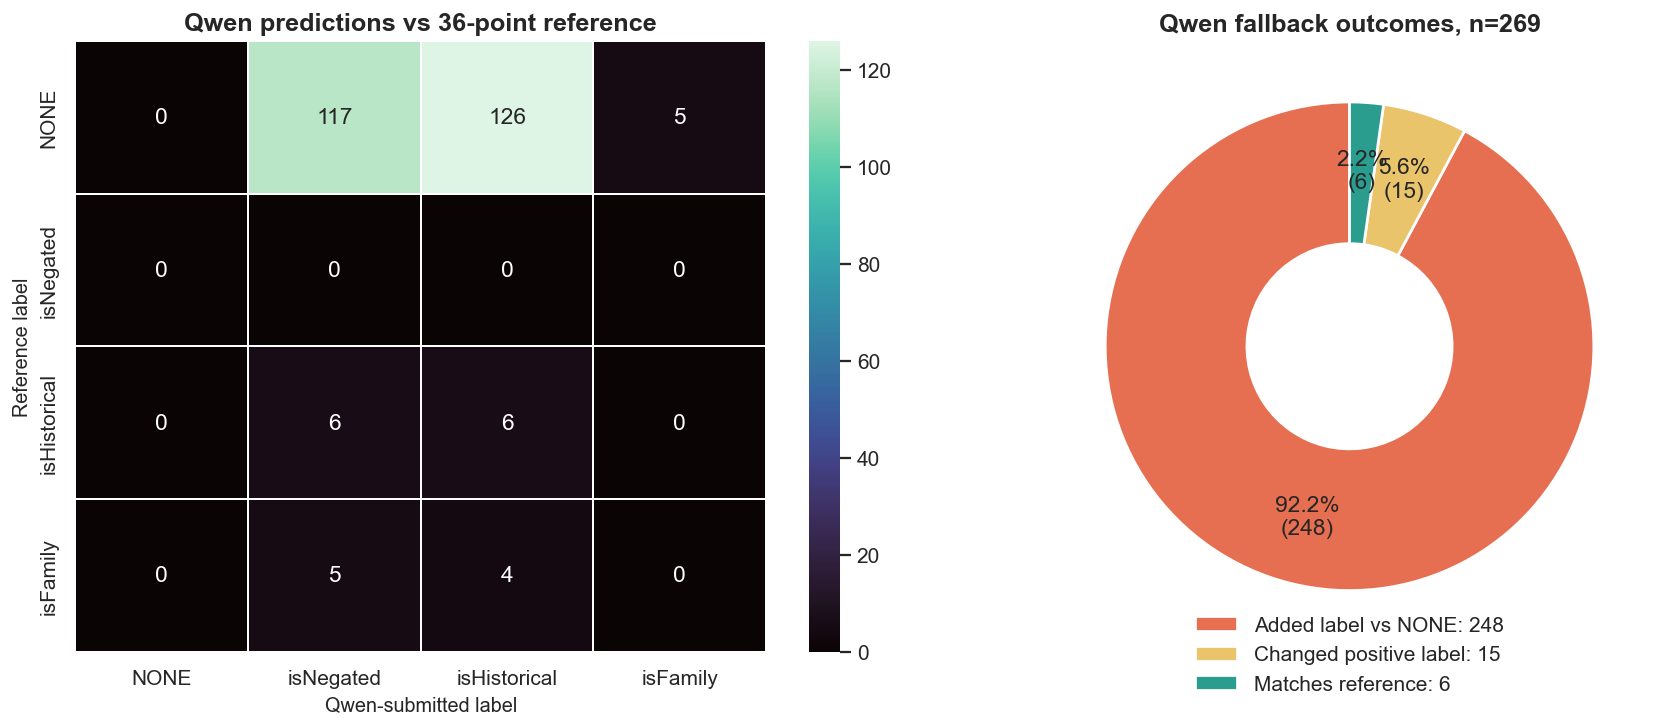

In [7]:
qwen = matched[matched['source_category'] == 'Qwen fallback'].copy()
qwen['proxy_outcome'] = np.select(
    [
        qwen['assertion_tag_current'] == qwen['assertion_tag_baseline'],
        (qwen['assertion_tag_baseline'] == 'NONE') & (qwen['assertion_tag_current'] != 'NONE'),
        (qwen['assertion_tag_baseline'] != 'NONE') & (qwen['assertion_tag_current'] != qwen['assertion_tag_baseline']),
    ],
    ['Matches reference', 'Added label vs NONE', 'Changed positive label'],
    default='Other',
)

qwen_tag_stats = (
    qwen.groupby('assertion_tag_current')
    .agg(
        predictions=('changed', 'size'),
        exact_matches=('agreement', 'sum'),
        proxy_false_positives=('assertion_tag_baseline', lambda s: (s == 'NONE').sum()),
    )
    .reset_index()
)
qwen_tag_stats['reference_agreement'] = qwen_tag_stats['exact_matches'] / qwen_tag_stats['predictions']
qwen_tag_stats['proxy_false_positive_rate'] = qwen_tag_stats['proxy_false_positives'] / qwen_tag_stats['predictions']

display(qwen_tag_stats.style.hide(axis='index').format({
    'predictions': '{:,}', 'exact_matches': '{:,}', 'proxy_false_positives': '{:,}',
    'reference_agreement': '{:.1%}', 'proxy_false_positive_rate': '{:.1%}',
}).background_gradient(subset=['proxy_false_positive_rate'], cmap='Reds'))

qwen_confusion = pd.crosstab(
    qwen['assertion_tag_baseline'], qwen['assertion_tag_current']
).reindex(index=ASSERTION_ORDER, columns=ASSERTION_ORDER, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.8))
sns.heatmap(qwen_confusion, annot=True, fmt=',d', cmap='mako', linewidths=1, ax=axes[0])
axes[0].set_title('Qwen predictions vs 36-point reference')
axes[0].set_xlabel('Qwen-submitted label')
axes[0].set_ylabel('Reference label')

outcome_counts = qwen['proxy_outcome'].value_counts()
outcome_colors = [
    PALETTE['good'] if x == 'Matches reference' else
    PALETTE['bad'] if x == 'Added label vs NONE' else
    PALETTE['warning']
    for x in outcome_counts.index
]
wedges, _, _ = axes[1].pie(
    outcome_counts.values,
    labels=None,
    autopct=lambda p: f'{p:.1f}%\n({round(p * outcome_counts.sum() / 100):,})',
    pctdistance=0.72,
    startangle=90,
    colors=outcome_colors,
    wedgeprops={'linewidth': 1.5, 'edgecolor': 'white', 'width': 0.58},
)
axes[1].legend(
    wedges,
    [f'{label}: {count:,}' for label, count in outcome_counts.items()],
    loc='lower center', bbox_to_anchor=(0.5, -0.10), ncol=1,
)
axes[1].set_title(f'Qwen fallback outcomes, n={len(qwen):,}')
plt.tight_layout()
plt.show()

## 6. Linguistic cue and scope analysis

Simple cue detection helps reveal a common failure mode: the model sees words such as *không* or *trước* but applies them to the wrong entity or interprets a diagnostic modifier as assertion scope.

Qwen label,predictions,reference agreement,expected cue present,added vs reference NONE
isNegated,128,0.0%,81.2%,91.4%
isHistorical,136,4.4%,33.1%,92.6%
isFamily,5,0.0%,60.0%,100.0%


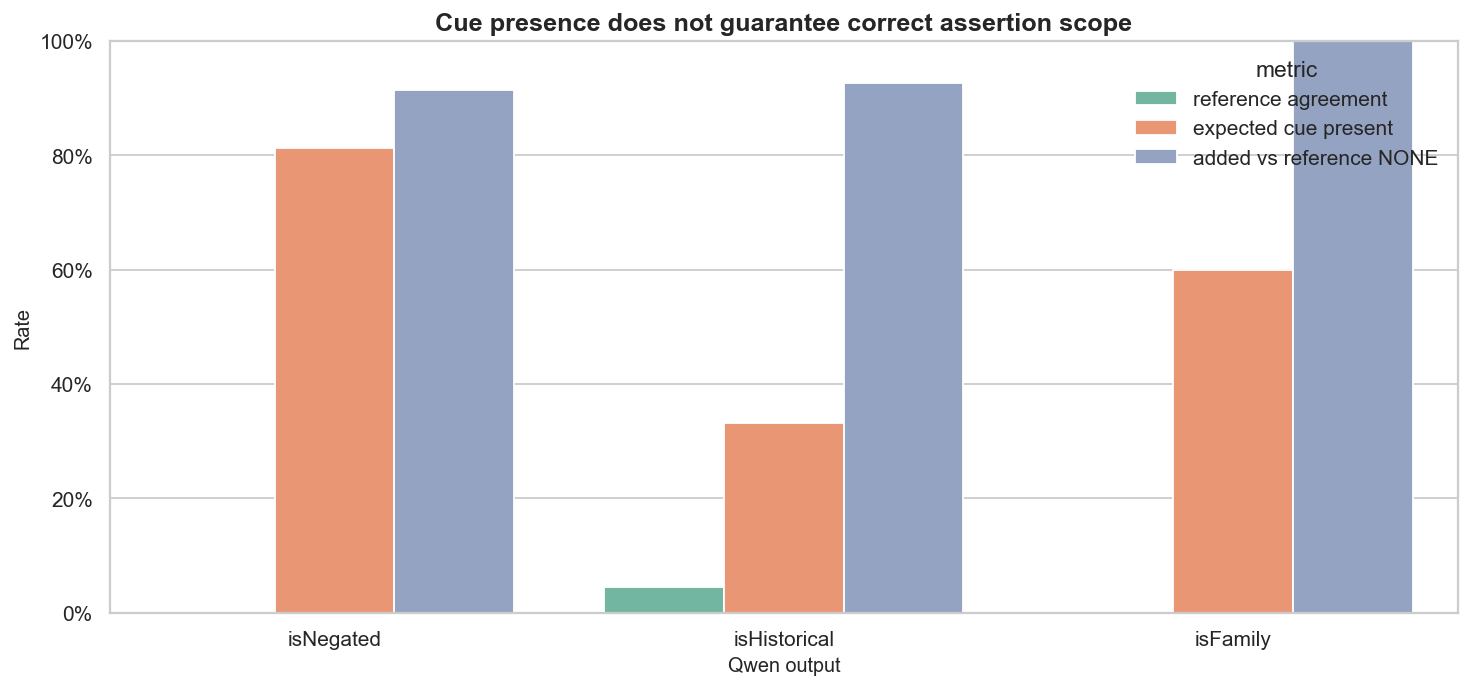

In [8]:
def normalized(value):
    value = unicodedata.normalize('NFC', str(value or '')).casefold()
    return re.sub(r'\s+', ' ', value).strip()

CUES = {
    'negation_cue': ['không', 'chưa', 'không có', 'không ghi nhận', 'phủ nhận'],
    'historical_cue': ['tiền sử', 'trước đây', 'đã từng', 'trước khi', 'cách đây', 'năm nay', 'tháng trước'],
    'family_cue': ['gia đình', 'mẹ', 'cha', 'bố', 'anh', 'chị', 'em', 'con', 'cháu'],
    'uncertainty_cue': ['nghi', 'có thể', 'khả năng', 'theo dõi', 'không loại trừ'],
}

for column, cues in CUES.items():
    qwen[column] = qwen['sentence'].map(
        lambda sentence: any(cue in normalized(sentence) for cue in cues)
    )

cue_summary = []
for tag in ['isNegated', 'isHistorical', 'isFamily']:
    subset = qwen[qwen['assertion_tag_current'] == tag]
    expected_cue = {
        'isNegated': 'negation_cue',
        'isHistorical': 'historical_cue',
        'isFamily': 'family_cue',
    }[tag]
    cue_summary.append({
        'Qwen label': tag,
        'predictions': len(subset),
        'reference agreement': subset['agreement'].mean() if len(subset) else np.nan,
        'expected cue present': subset[expected_cue].mean() if len(subset) else np.nan,
        'added vs reference NONE': (subset['assertion_tag_baseline'] == 'NONE').mean() if len(subset) else np.nan,
    })
cue_summary = pd.DataFrame(cue_summary)
display(cue_summary.style.hide(axis='index').format({
    'predictions': '{:,}', 'reference agreement': '{:.1%}',
    'expected cue present': '{:.1%}', 'added vs reference NONE': '{:.1%}',
}).background_gradient(subset=['added vs reference NONE'], cmap='Reds'))

cue_long = cue_summary.melt(
    id_vars=['Qwen label', 'predictions'],
    value_vars=['reference agreement', 'expected cue present', 'added vs reference NONE'],
    var_name='metric', value_name='rate'
)
fig, ax = plt.subplots(figsize=(11.5, 5.5))
sns.barplot(data=cue_long, x='Qwen label', y='rate', hue='metric', palette='Set2', ax=ax)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda x, pos: f'{x:.0%}')
ax.set_title('Cue presence does not guarantee correct assertion scope')
ax.set_xlabel('Qwen output')
ax.set_ylabel('Rate')
plt.tight_layout()
plt.show()

## 7. Concrete cases to inspect

The tables below are the practical debugging payload. Start with the largest categories, then add each confirmed failure as a regression test.

In [9]:
case_columns = [
    'file', 'text', 'type', 'assertion_tag_baseline', 'assertion_tag_current',
    'primary_tag', 'qwen_tag', 'sentence'
]

qwen_added = qwen[
    (qwen['assertion_tag_baseline'] == 'NONE') &
    (qwen['assertion_tag_current'] != 'NONE')
].copy()
qwen_added['risk_score'] = (
    (~qwen_added['negation_cue']).astype(int) * (qwen_added['assertion_tag_current'] == 'isNegated') * 2 +
    (~qwen_added['historical_cue']).astype(int) * (qwen_added['assertion_tag_current'] == 'isHistorical') * 2 +
    (~qwen_added['family_cue']).astype(int) * (qwen_added['assertion_tag_current'] == 'isFamily') * 2
)
qwen_added = qwen_added.sort_values(['risk_score', 'file_id_baseline'], ascending=[False, True])

lost_assertions = matched[
    (matched['assertion_tag_baseline'] != 'NONE') &
    (matched['assertion_tag_current'] == 'NONE')
].sort_values(['source_category', 'file_id_baseline'])

label_flips = matched[
    (matched['assertion_tag_baseline'] != 'NONE') &
    (matched['assertion_tag_current'] != 'NONE') &
    (matched['assertion_tag_baseline'] != matched['assertion_tag_current'])
].sort_values(['source_category', 'file_id_baseline'])

print(f'Qwen-added labels vs baseline NONE: {len(qwen_added):,}')
display(qwen_added[case_columns + ['negation_cue', 'historical_cue', 'family_cue']].head(40))

print(f'\nBaseline positive assertion lost in current output: {len(lost_assertions):,}')
display(lost_assertions[case_columns + ['source_category']].head(40))

print(f'\nPositive-label flips: {len(label_flips):,}')
display(label_flips[case_columns + ['source_category']].head(40))

Qwen-added labels vs baseline NONE: 248

Baseline positive assertion lost in current output: 120

Positive-label flips: 27


,file,text,type,assertion_tag_baseline,assertion_tag_current,primary_tag,qwen_tag,sentence,negation_cue,historical_cue,family_cue
116,4.json,đau vùng hạ sườn phải,TRIỆU_CHỨNG,NONE,isHistorical,None,isHistorical,"Khởi phát bệnh cách thời điểm nhập viện vài tuần với triệu chứng [ENTITY], kèm chướng bụng và buồn nôn thoáng qua.",False,False,False
178,7.json,lú lẫn,TRIỆU_CHỨNG,NONE,isNegated,None,isNegated,"Thuốc trước khi nhập viện lần này: seroquel (ngụ ý, vì bệnh nhân cho rằng [ENTITY], chóng mặt, khó nhìn gần có thể liên quan đến thuốc).",False,True,False
190,7.json,Lú lẫn,TRIỆU_CHỨNG,NONE,isHistorical,None,isHistorical,[ENTITY]: từng đợt.,False,False,False
203,7.json,Đột sống thắt lưng,CHẨN_ĐOÁN,NONE,isHistorical,None,isHistorical,Các thủ thuật đã thực hiện: chọc dò dịch não tủy ([ENTITY]).,False,False,False
249,12.json,ho ra máu,TRIỆU_CHỨNG,NONE,isHistorical,None,isHistorical,[ENTITY] x3 đêm qua.,False,False,False
252,12.json,ho,TRIỆU_CHỨNG,NONE,isHistorical,None,isHistorical,Tối qua tiến triển thành 3 cơn [ENTITY] đánh thức bệnh nhân khỏi giấc ngủ và có đờm có màu hồng.,False,False,False
317,16.json,đau bụng,TRIỆU_CHỨNG,NONE,isHistorical,None,isHistorical,Bệnh nhân đã có [ENTITY] gián đoạn kể từ khi phẫu thuật.,False,False,False
365,17.json,sốt,TRIỆU_CHỨNG,NONE,isNegated,None,isNegated,"cảm thấy tốt hơn sau khi dẫn lưu áp xe, và lại thấy đỡ [ENTITY] và đau cổ.",False,False,False
416,20.json,Nhồi máu cơ tim,CHẨN_ĐOÁN,NONE,isHistorical,None,isHistorical,bệnh tim mạch do xơ vữa động mạch với [ENTITY] gần đây.,False,False,False
449,20.json,Nhồi máu cơ tim,CHẨN_ĐOÁN,NONE,isHistorical,None,isHistorical,rung nhĩ kịch phát liên tục kể từ [ENTITY].,False,False,False


,file,text,type,assertion_tag_baseline,assertion_tag_current,primary_tag,qwen_tag,sentence,source_category
148,5.json,bệnh tim mạch,CHẨN_ĐOÁN,isHistorical,NONE,None,None,[ENTITY] do xơ vữa động mạch.,Fallback empty
173,7.json,ho,TRIỆU_CHỨNG,isHistorical,NONE,None,None,[ENTITY] Rối loạn cảm xúc (trầm cảm) (tiền sử giai đoạn trầm cảm không đặc hiệu).,Fallback empty
182,7.json,chóng mặt,TRIỆU_CHỨNG,isFamily,NONE,None,None,cảm giác [ENTITY].,Fallback empty
186,7.json,ảo giác thị giác,TRIỆU_CHỨNG,isFamily,NONE,None,None,[ENTITY] (ảo giác thị giác).,Fallback empty
187,7.json,ảo giác thị giác,TRIỆU_CHỨNG,isFamily,NONE,None,None,ảo giác thị giác ([ENTITY]).,Fallback empty
188,7.json,Ảo thanh,TRIỆU_CHỨNG,isFamily,NONE,None,None,[ENTITY] (AH) (ảo giác thính giác).,Fallback empty
189,7.json,ảo giác thính giác,TRIỆU_CHỨNG,isFamily,NONE,None,None,Ảo thanh (AH) ([ENTITY]).,Fallback empty
194,7.json,rối loạn thị giác,TRIỆU_CHỨNG,isHistorical,NONE,None,None,[ENTITY]: nhìn thấy con cái ở góc mắt.,Fallback empty
196,7.json,ảo giác thị giác,TRIỆU_CHỨNG,isFamily,NONE,None,None,"[ENTITY], Ảo thanh (AH): có vẻ là ảo giác hơn là ảo ảnh thực sự.",Fallback empty
197,7.json,Ảo thanh,TRIỆU_CHỨNG,isFamily,NONE,None,None,"ảo giác thị giác, [ENTITY] (AH): có vẻ là ảo giác hơn là ảo ảnh thực sự.",Fallback empty


,file,text,type,assertion_tag_baseline,assertion_tag_current,primary_tag,qwen_tag,sentence,source_category
662,33.json,ho có đờm trắng,TRIỆU_CHỨNG,isFamily,isHistorical,isHistorical,None,tiền sử [ENTITY].,Primary rule
875,40.json,đau buốt khi,TRIỆU_CHỨNG,isFamily,isNegated,isNegated,None,"đi tiểu nhiều lần vào ban đêm, không có [ENTITY] đi tiểu.",Primary rule
881,40.json,đau ngực,TRIỆU_CHỨNG,isFamily,isNegated,isNegated,None,Phủ nhận [ENTITY].,Primary rule
882,40.json,buồn nôn,TRIỆU_CHỨNG,isFamily,isNegated,isNegated,None,Phủ nhận [ENTITY]/nôn.,Primary rule
883,40.json,nôn,TRIỆU_CHỨNG,isFamily,isNegated,isNegated,None,Phủ nhận buồn nôn/[ENTITY].,Primary rule
884,40.json,đổ mồ hôi đêm,TRIỆU_CHỨNG,isFamily,isNegated,isNegated,None,Phủ nhận [ENTITY].,Primary rule
885,40.json,khó thở,TRIỆU_CHỨNG,isFamily,isNegated,isNegated,None,Phủ nhận [ENTITY] khi nằm.,Primary rule
886,40.json,khó thở,TRIỆU_CHỨNG,isFamily,isNegated,isNegated,None,Phủ nhận [ENTITY] khi nằm đột ngột (paroxysmal nocturnal dyspnea).,Primary rule
1513,70.json,khó chịu,TRIỆU_CHỨNG,isFamily,isHistorical,isHistorical,None,"Các tập tương tự trước đây: Từng bị [ENTITY] tương tự trong quá khứ, luôn thuyên giảm khi dùng thuốc.",Primary rule
1532,70.json,buồn nôn,TRIỆU_CHỨNG,isFamily,isNegated,isNegated,None,Không có [ENTITY].,Primary rule


## 8. Per-file regression concentration

If a small number of documents dominate the changes, inspect their normalization and sentence construction first. If changes scale with Qwen usage across many documents, fallback policy is the stronger suspect.

Pearson correlation between Qwen fallback volume and assertion changes by file: 0.751


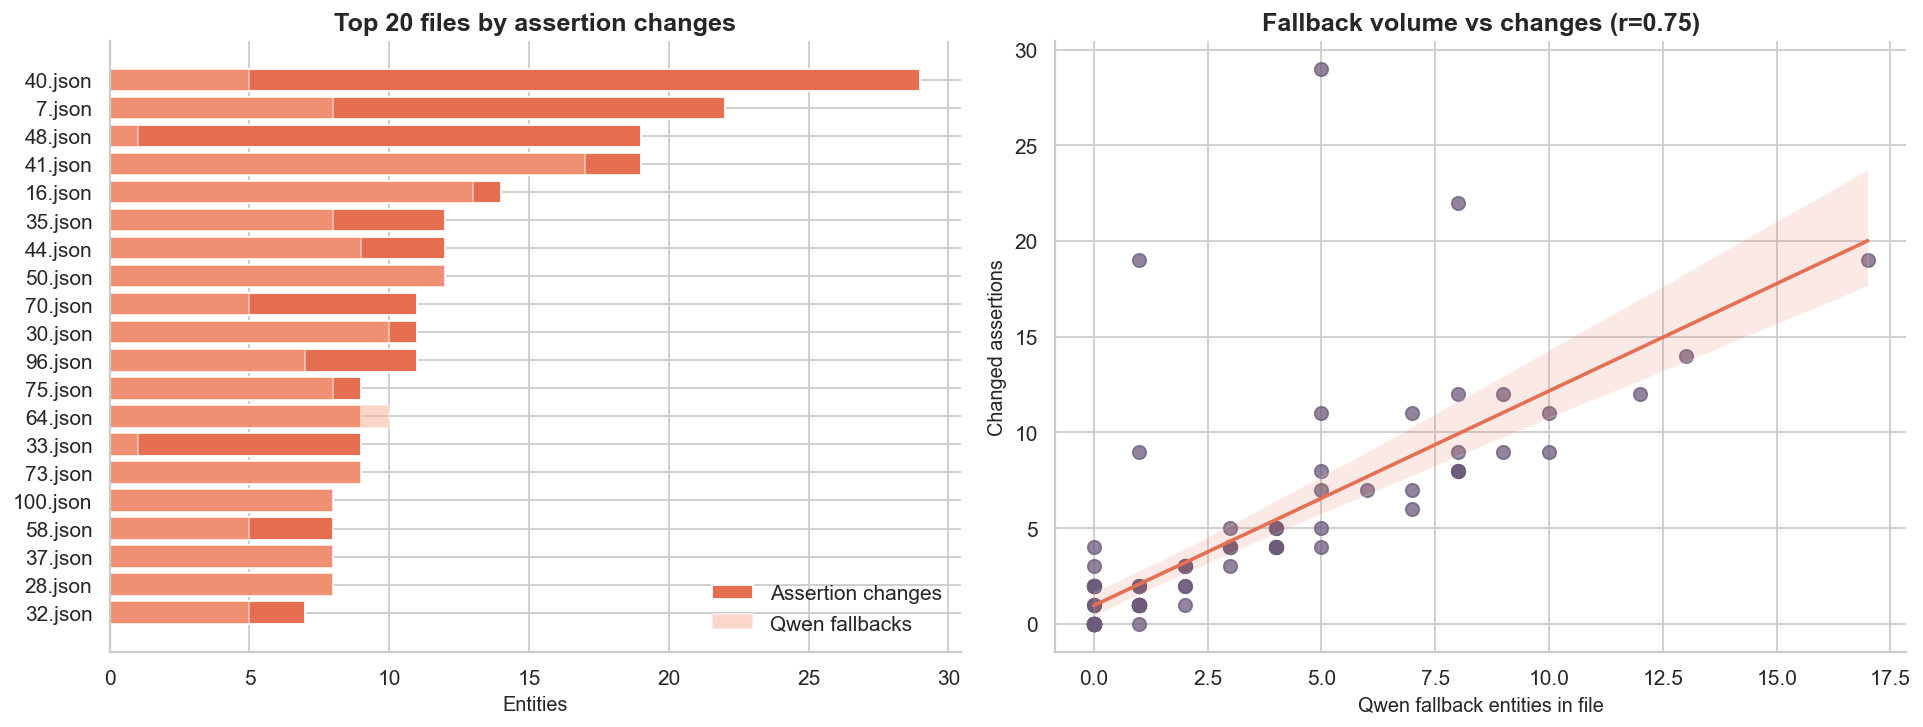

file,file_id_baseline,matched_entities,assertion_changes,qwen_fallbacks,primary_rules,change_rate
40.json,40,41,29,5,10,70.7%
7.json,7,33,22,8,3,66.7%
41.json,41,58,19,17,6,32.8%
48.json,48,44,19,1,12,43.2%
16.json,16,47,14,13,3,29.8%
44.json,44,35,12,9,0,34.3%
35.json,35,41,12,8,2,29.3%
50.json,50,51,12,12,2,23.5%
70.json,70,46,11,5,11,23.9%
96.json,96,26,11,7,1,42.3%


In [10]:
per_file = (
    matched.groupby(['file', 'file_id_baseline'])
    .agg(
        matched_entities=('changed', 'size'),
        assertion_changes=('changed', 'sum'),
        qwen_fallbacks=('source_category', lambda s: (s == 'Qwen fallback').sum()),
        primary_rules=('source_category', lambda s: (s == 'Primary rule').sum()),
    )
    .reset_index()
)
per_file['change_rate'] = per_file['assertion_changes'] / per_file['matched_entities']
per_file = per_file.sort_values('assertion_changes', ascending=False)

correlation = per_file[['qwen_fallbacks', 'assertion_changes']].corr().iloc[0, 1]
print(f'Pearson correlation between Qwen fallback volume and assertion changes by file: {correlation:.3f}')

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
top_files = per_file.head(20).sort_values('assertion_changes')
axes[0].barh(top_files['file'], top_files['assertion_changes'], color=PALETTE['bad'], label='Assertion changes')
axes[0].barh(top_files['file'], top_files['qwen_fallbacks'], color=PALETTE['qwen'], alpha=0.5, label='Qwen fallbacks')
axes[0].set_title('Top 20 files by assertion changes')
axes[0].set_xlabel('Entities')
axes[0].legend()

sns.regplot(
    data=per_file, x='qwen_fallbacks', y='assertion_changes',
    scatter_kws={'s': 55, 'alpha': 0.75, 'color': PALETTE['primary']},
    line_kws={'color': PALETTE['bad'], 'linewidth': 2}, ax=axes[1]
)
axes[1].set_title(f'Fallback volume vs changes (r={correlation:.2f})')
axes[1].set_xlabel('Qwen fallback entities in file')
axes[1].set_ylabel('Changed assertions')

sns.despine()
plt.tight_layout()
plt.show()

display(per_file.head(25).style.hide(axis='index').format({'change_rate': '{:.1%}'}))

## 9. Automatically generated findings and recommended fixes

In [11]:
changed_count = int(matched['changed'].sum())
qwen_changed = int(qwen['changed'].sum())
qwen_added_count = int(((qwen['assertion_tag_baseline'] == 'NONE') & (qwen['assertion_tag_current'] != 'NONE')).sum())
qwen_agreement = float(qwen['agreement'].mean()) if len(qwen) else float('nan')

largest_transition = changed_transitions.iloc[0] if len(changed_transitions) else None
largest_text = (
    f"{largest_transition['assertion_tag_baseline']} → {largest_transition['assertion_tag_current']} "
    f"({int(largest_transition['count']):,} entities)"
    if largest_transition is not None else 'No changed transition'
)

findings = f"""
### Findings

- **Entity confound:** only **{len(matched):,}** records align exactly; **{len(old_only):,}** baseline-side and **{len(new_only):,}** current-side records are absent or mutated. These changes cannot be attributed to Qwen.
- **Assertion regression:** **{changed_count:,} / {len(matched):,} ({changed_count / len(matched):.1%})** identical entities changed assertion.
- **Qwen reach:** Qwen supplied **{len(qwen):,}** assertions on the matched population.
- **Qwen proxy agreement:** **{qwen_agreement:.1%}** match the 36-point reference; **{qwen_changed:,}** differ.
- **Likely over-assertion:** Qwen added a positive label to **{qwen_added_count:,}** entities whose 36-point assertion was `NONE`.
- **Largest transition:** **{largest_text}**.

### Why the fallback is likely hurting

1. A null primary result is treated as permission to trust Qwen, rather than as insufficient evidence.
2. There is no confidence threshold, abstention calibration, or agreement requirement.
3. Sentence-wide cue detection causes scope errors: words such as `không`, `trước`, or a family noun can refer to a modifier or another entity.
4. Diagnostic names containing negation-like wording (for example “không đặc hiệu” or “không do chấn thương”) are especially vulnerable.
5. The normalized sentence builder can produce fragments or awkward contexts, which makes Qwen classify malformed entities confidently.

### Recommended debugging order

1. **Ablate Qwen:** format the same current entities with all Qwen-only tags set to `NONE`; submit or evaluate this independently.
2. **Preserve abstention:** accept Qwen only when it emits structured confidence and exceeds a calibrated per-label threshold.
3. **Add scope gates:** require a relevant cue near `[ENTITY]`, while blocking diagnostic modifiers such as `không đặc hiệu` and `không do chấn thương`.
4. **Fix sentence/entity quality first:** reject fragment entities and malformed contexts before assertion inference.
5. **Create a labeled validation slice:** manually label the top 100 rows from the case tables and calculate real precision/recall for primary-only, Qwen-only, and the combined policy.
6. **Turn confirmed failures into tests:** every false case above should become a deterministic regression fixture.
"""
display(Markdown(findings))


### Findings

- **Entity confound:** only **2,016** records align exactly; **211** baseline-side and **220** current-side records are absent or mutated. These changes cannot be attributed to Qwen.
- **Assertion regression:** **397 / 2,016 (19.7%)** identical entities changed assertion.
- **Qwen reach:** Qwen supplied **269** assertions on the matched population.
- **Qwen proxy agreement:** **2.2%** match the 36-point reference; **263** differ.
- **Likely over-assertion:** Qwen added a positive label to **248** entities whose 36-point assertion was `NONE`.
- **Largest transition:** **NONE → isHistorical (128 entities)**.

### Why the fallback is likely hurting

1. A null primary result is treated as permission to trust Qwen, rather than as insufficient evidence.
2. There is no confidence threshold, abstention calibration, or agreement requirement.
3. Sentence-wide cue detection causes scope errors: words such as `không`, `trước`, or a family noun can refer to a modifier or another entity.
4. Diagnostic names containing negation-like wording (for example “không đặc hiệu” or “không do chấn thương”) are especially vulnerable.
5. The normalized sentence builder can produce fragments or awkward contexts, which makes Qwen classify malformed entities confidently.

### Recommended debugging order

1. **Ablate Qwen:** format the same current entities with all Qwen-only tags set to `NONE`; submit or evaluate this independently.
2. **Preserve abstention:** accept Qwen only when it emits structured confidence and exceeds a calibrated per-label threshold.
3. **Add scope gates:** require a relevant cue near `[ENTITY]`, while blocking diagnostic modifiers such as `không đặc hiệu` and `không do chấn thương`.
4. **Fix sentence/entity quality first:** reject fragment entities and malformed contexts before assertion inference.
5. **Create a labeled validation slice:** manually label the top 100 rows from the case tables and calculate real precision/recall for primary-only, Qwen-only, and the combined policy.
6. **Turn confirmed failures into tests:** every false case above should become a deterministic regression fixture.


## 10. Export audit tables

These CSV files make it easy to annotate errors manually or share them with teammates.

In [12]:
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

validation.to_csv(EXPORT_DIR / 'validation_summary.csv', index=False, encoding='utf-8-sig')
source_stats.to_csv(EXPORT_DIR / 'decision_source_stats.csv', index=False, encoding='utf-8-sig')
changed_transitions.to_csv(EXPORT_DIR / 'assertion_transitions.csv', index=False, encoding='utf-8-sig')
qwen_tag_stats.to_csv(EXPORT_DIR / 'qwen_tag_proxy_metrics.csv', index=False, encoding='utf-8-sig')
per_file.to_csv(EXPORT_DIR / 'per_file_regression.csv', index=False, encoding='utf-8-sig')
qwen_added[case_columns + ['negation_cue', 'historical_cue', 'family_cue']].to_csv(
    EXPORT_DIR / 'qwen_added_labels_for_review.csv', index=False, encoding='utf-8-sig'
)
lost_assertions[case_columns + ['source_category']].to_csv(
    EXPORT_DIR / 'lost_baseline_assertions.csv', index=False, encoding='utf-8-sig'
)
label_flips[case_columns + ['source_category']].to_csv(
    EXPORT_DIR / 'positive_label_flips.csv', index=False, encoding='utf-8-sig'
)

print(f'Exported audit tables to: {EXPORT_DIR.resolve()}')
for path in sorted(EXPORT_DIR.glob('*.csv')):
    print(f'  {path.name}: {path.stat().st_size:,} bytes')

Exported audit tables to: C:\Users\ACER\OneDrive\Documents\ai race\assertion_debug_report_outputs
  assertion_transitions.csv: 229 bytes
  decision_source_stats.csv: 338 bytes
  lost_baseline_assertions.csv: 14,626 bytes
  per_file_regression.csv: 3,465 bytes
  positive_label_flips.csv: 3,922 bytes
  qwen_added_labels_for_review.csv: 44,727 bytes
  qwen_tag_proxy_metrics.csv: 242 bytes
  validation_summary.csv: 293 bytes
